Import the Dependencies

In [1]:
%matplotlib notebook
from IPython.display import Image, display
import io
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

Data Collection & Analysis

In [2]:
#loading the data from csv file to a Pandas DataFrame
insurence_dataset = pd.read_csv(r'C:\Users\acer\OneDrive\Desktop\medical insurence\insurance.csv')

In [3]:
#first 5 rows of the dataset
insurence_dataset.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# number of rows and columns in the dataset
insurence_dataset.shape

(1338, 7)

In [5]:
#getting some information about the dataset
insurence_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


Categorical Feature
- Sex
- Smoker
- Region

In [6]:
# checking for missing values in the dataset
insurence_dataset.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Data Analysis

In [7]:
# statistical measures about the dataset
insurence_dataset.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

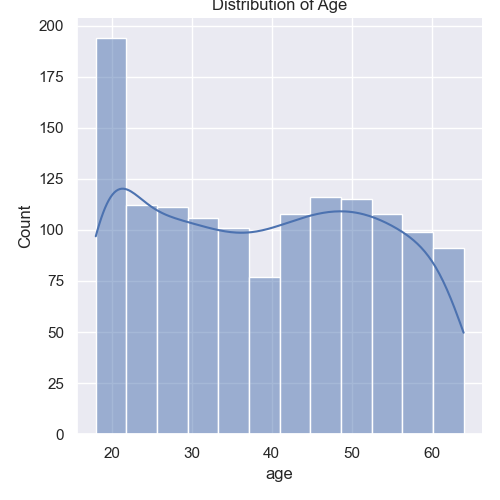

In [8]:
# distribution of the age value
sns.set()
plt.figure(figsize=(6,6))
sns.displot(insurence_dataset['age'], kde=True)
plt.title('Distribution of Age')
plt.savefig('age_distribution.png')
plt.close()

from IPython.display import Image
Image('age_distribution.png')


<IPython.core.display.Javascript object>

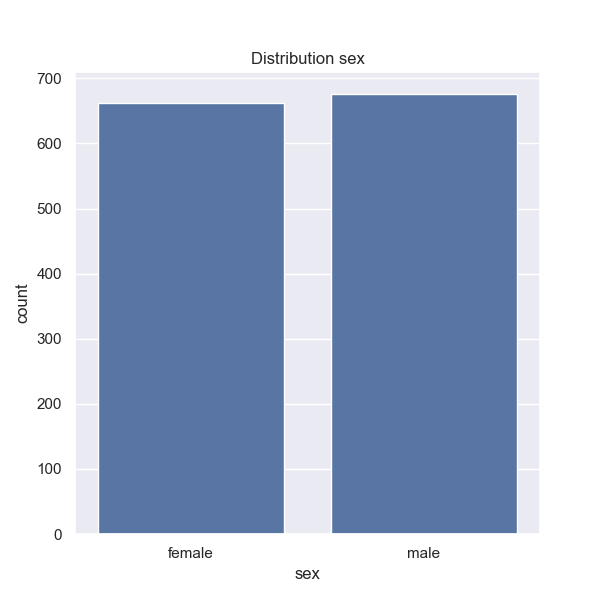

In [9]:
# Gender columns
fig, ax = plt.subplots(figsize=(6,6))
sns.countplot(x='sex', data=insurence_dataset, ax=ax)
ax.set_title('Distribution sex')

buf = io.BytesIO()
fig.savefig(buf, format='png')
buf.seek(0)
display(Image(data=buf.read()))
plt.close(fig)


In [10]:
insurence_dataset['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

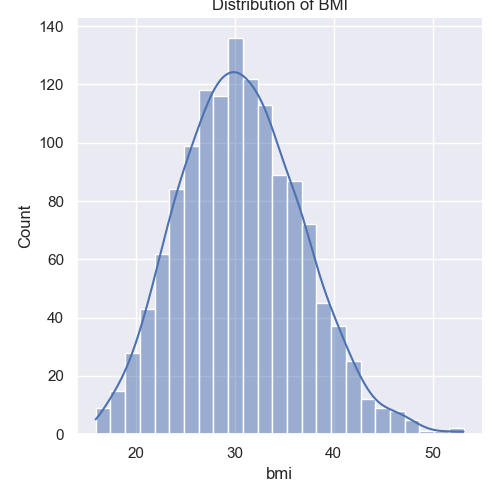

In [14]:
plt.figure(figsize=(6,6))
sns.displot(insurence_dataset['bmi'], kde=True)
plt.title('Distribution of BMI')
plt.savefig('BMI_distribution.png')
plt.close()

from IPython.display import Image
Image('BMI_distribution.png')


Normal Bmi Range --> 18.5 to 24.9

<IPython.core.display.Javascript object>

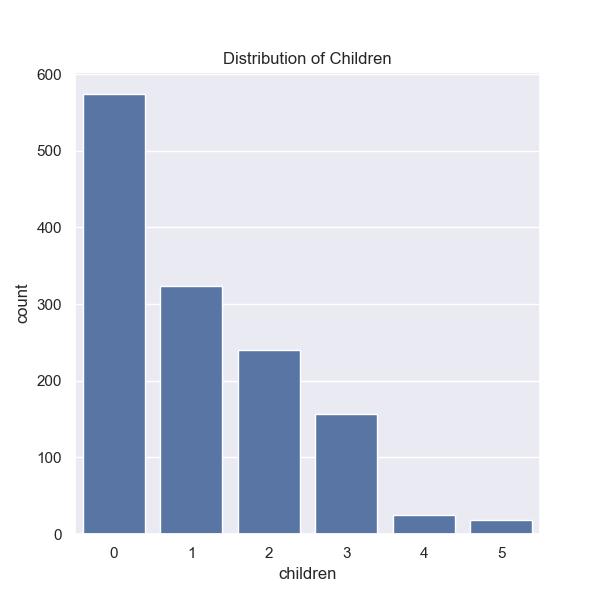

In [15]:
# children columns
fig, ax = plt.subplots(figsize=(6,6))
sns.countplot(x='children', data=insurence_dataset, ax=ax)
ax.set_title('Distribution of Children')

buf = io.BytesIO()
fig.savefig(buf, format='png')
buf.seek(0)
display(Image(data=buf.read()))
plt.close(fig)


In [16]:
insurence_dataset['children'].value_counts()

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

<IPython.core.display.Javascript object>

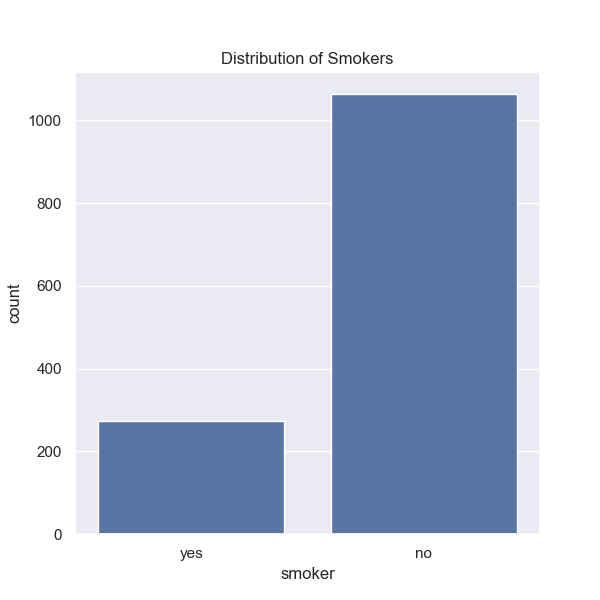

In [17]:
# children columns
fig, ax = plt.subplots(figsize=(6,6))
sns.countplot(x='smoker', data=insurence_dataset, ax=ax)
ax.set_title('Distribution of Smokers')

buf = io.BytesIO()
fig.savefig(buf, format='png')
buf.seek(0)
display(Image(data=buf.read()))
plt.close(fig)

In [18]:
insurence_dataset['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

<IPython.core.display.Javascript object>

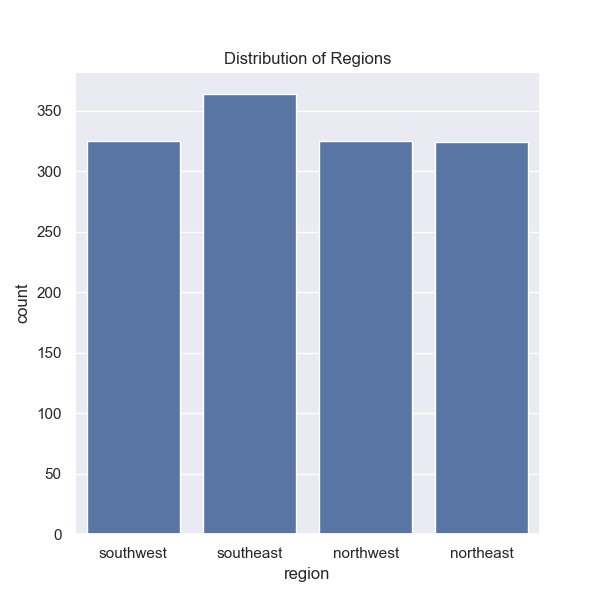

In [19]:
# Region columns
fig, ax = plt.subplots(figsize=(6,6))
sns.countplot(x='region', data=insurence_dataset, ax=ax)
ax.set_title('Distribution of Regions')

buf = io.BytesIO()
fig.savefig(buf, format='png')
buf.seek(0)
display(Image(data=buf.read()))
plt.close(fig)

In [20]:
insurence_dataset['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

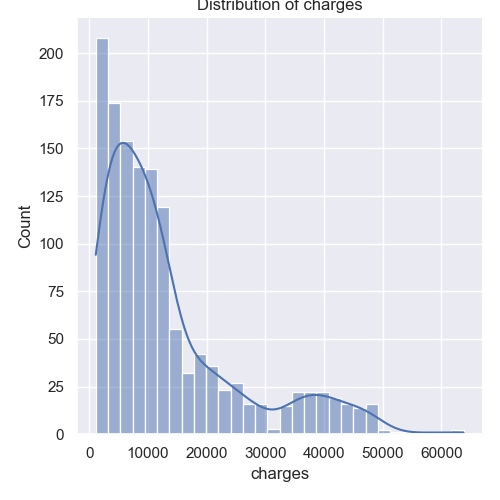

In [22]:
#Distribution of the charges value
plt.figure(figsize=(6,6))
sns.displot(insurence_dataset['charges'], kde=True)
plt.title('Distribution of charges')
plt.savefig('charges_distribution.png')
plt.close()

from IPython.display import Image
Image('charges_distribution.png')

Data preprocessing

Encoding the categorical features

In [23]:
# Encoding the sex colunm
insurence_dataset.replace({'sex':{'male':0,'female':1}},inplace=True)

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,no,northwest,10600.54830
1334,18,1,31.920,0,no,northeast,2205.98080
1335,18,1,36.850,0,no,southeast,1629.83350
1336,21,1,25.800,0,no,southwest,2007.94500


In [24]:
# Encoding the 'smoker' column
insurence_dataset.replace({'smoker':{'yes':0,'no':1}},inplace=True)

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,0,southwest,16884.92400
1,18,0,33.770,1,1,southeast,1725.55230
2,28,0,33.000,3,1,southeast,4449.46200
3,33,0,22.705,0,1,northwest,21984.47061
4,32,0,28.880,0,1,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,1,northwest,10600.54830
1334,18,1,31.920,0,1,northeast,2205.98080
1335,18,1,36.850,0,1,southeast,1629.83350
1336,21,1,25.800,0,1,southwest,2007.94500


In [25]:
# Encoding the 'region' column
insurence_dataset.replace({'region':{'southeast':0,'southwest':1,'northeast':2,'northwest':3}},inplace=True)

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,0,1,16884.92400
1,18,0,33.770,1,1,0,1725.55230
2,28,0,33.000,3,1,0,4449.46200
3,33,0,22.705,0,1,3,21984.47061
4,32,0,28.880,0,1,3,3866.85520
...,...,...,...,...,...,...,...
1333,50,0,30.970,3,1,3,10600.54830
1334,18,1,31.920,0,1,2,2205.98080
1335,18,1,36.850,0,1,0,1629.83350
1336,21,1,25.800,0,1,1,2007.94500


Spliting the Feature and Target

In [30]:
x = insurence_dataset.drop(columns='charges')
y = insurence_dataset['charges']

In [32]:
print(x)

      age sex     bmi  children smoker region
0      19   1  27.900         0      0      1
1      18   0  33.770         1      1      0
2      28   0  33.000         3      1      0
3      33   0  22.705         0      1      3
4      32   0  28.880         0      1      3
...   ...  ..     ...       ...    ...    ...
1333   50   0  30.970         3      1      3
1334   18   1  31.920         0      1      2
1335   18   1  36.850         0      1      0
1336   21   1  25.800         0      1      1
1337   61   1  29.070         0      0      3

[1338 rows x 6 columns]


In [33]:
print(y)

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1338, dtype: float64


Spliting the Data Into Traning Data & Testing Data

In [34]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=2)

In [35]:
print(x.shape, x_train.shape, x_test.shape)

(1338, 6) (1070, 6) (268, 6)


Model Training 

Linear Regression

In [36]:
#Loading the Linear Regression model
regressor = LinearRegression()

In [38]:
regressor.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


Model Evaluation

In [39]:
# predicting on training data
training_data_prediction = regressor.predict(x_train)

In [41]:
# R square value
r2_train = metrics.r2_score(y_train, training_data_prediction)
print('R square value : ', r2_train)

R square value :  0.751505643411174


In [43]:
# predicting on testing data
testing_data_prediction = regressor.predict(x_test)

In [44]:
# R square value
r2_test = metrics.r2_score(y_test, testing_data_prediction)
print('R square value : ', r2_test)

R square value :  0.7447273869684077


Building a Predictive System

In [ ]:
input_data = (19, 0, 27.9, 0, 1, 2)
# changing the input_data to a numpy array
input_data_as_numpy_array = np.asarray(input_data)
# reshape the array
input_data_reshaped = input_data_as_numpy_array.reshape(1, -1)
prediction = regressor.predict(input_data_reshaped)
print('Prediction : ', prediction)
print('The insurance cost is USD ', prediction[0])


Prediction :  [1855.74297048]
The insurance cost is USD  1855.7429704814367


c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
